# Imports and setup

In [28]:
# @title Imports
from alphagenome import colab_utils

from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import model_condition

from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript
from alphagenome.data import gene_expression_data, track_data


from alphagenome.visualization import plot_components

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import gc
from dotenv import load_dotenv
import seaborn as sns
import glob
import pickle
pd.set_option('display.max_rows', None)

load_dotenv(dotenv_path=".env")
API_KEYS = [v for _, v in sorted(
    ((k, os.environ[k].strip()) for k in os.environ
     if k.startswith("AG_API_KEY_") and k.removeprefix("AG_API_KEY_").isdigit()),
    key=lambda kv: int(kv[0].removeprefix("AG_API_KEY_")),
) if v]


In [7]:
dna_model = dna_client.create(API_KEYS[5])

In [29]:
# Load GENCODE gene and transcript annotations
# GENCODE v46 gene annotations for the hg38 human genome assembly.

gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Get the MANE transcripts (one curated transcript per locus).
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts_mane = gene_annotation.filter_to_mane_select_transcript(
    gtf_transcripts
)

# Set up transcript extractors using the information in the GTF file.
transcript_extractor_mane = transcript.TranscriptExtractor(
    gtf_transcripts_mane
)

# Filter to protein-coding genes and highly supported transcripts.
gtf_transcript = gene_annotation.filter_transcript_support_level(
    gene_annotation.filter_protein_coding(gtf), ['1']
)

# Extractor for identifying transcripts in a region.
transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)

# Also define an extractor that fetches only the longest transcript per gene.
gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
    gtf_transcript
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gtf_longest_transcript
)



In [9]:
# Load all conditions
conditions = dna_model.supported_conditions(dna_client.Organism.HOMO_SAPIENS)

# Explore conditions

In [10]:
print(f'{len(conditions)} supported human conditions')
conditions.head()

2799 supported human conditions


,condition,biosample_type,biosample_name,atac,cage,dnase,rna_seq,chip_histone,chip_tf,splice_sites,splice_site_usage,splice_junctions,contact_maps,sc_atac,sc_gene_expression,methylation
0,CL:0000047,primary_cell,neural stem cell,imputed_supported,imputed_exploratory,observed,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
1,CL:0000100,in_vitro_differentiated_cells,motor neuron,observed,imputed_exploratory,imputed_supported,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
2,CL:0000115,primary_cell,endothelial cell,imputed_supported,imputed_exploratory,observed,observed,imputed_supported,observed,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
3,CL:0000134,primary_cell,mesenchymal stem cell,imputed_supported,imputed_exploratory,observed,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
4,CL:0000136,primary_cell,adipocyte,imputed_supported,imputed_exploratory,observed,imputed_supported,observed,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported


## Heart conditions

In [11]:
heart = conditions[
    (conditions['biosample_name'].str.contains('heart')) | (conditions['biosample_name'].str.contains('cardiac'))
]

heart[['condition', 'biosample_type', 'biosample_name']]#['biosample_name'].tolist() # 

,condition,biosample_type,biosample_name
19,CL:0000746,primary_cell,cardiac muscle cell
603,UBERON:0000948,tissue,heart
604,UBERON:0000948_CL:0000235,primary_cell,heart macrophage
605,UBERON:0000948_CL:0000569,primary_cell,heart cardiac mesenchymal cell
606,UBERON:0000948_CL:0000669,primary_cell,heart pericyte
607,UBERON:0000948_CL:0000746,primary_cell,heart cardiac muscle cell
608,UBERON:0000948_CL:0002098,primary_cell,heart regular cardiac myocyte
609,UBERON:0000948_CL:0002129,primary_cell,heart regular atrial cardiac myocyte
610,UBERON:0000948_CL:0002350,primary_cell,heart endocardial cell
611,UBERON:0000948_CL:0002548,primary_cell,heart fibroblast of cardiac tissue


## Possible conditions

- UBERON:0002084_CL:0000746, primary_cell, heart left ventricle cardiac muscle cell
- UBERON:0002084, tissue, heart left ventricle
- UBERON:0000948_CL:0000746, primary_cell, heart cardiac muscle cell
- UBERON:0000948_CL:0002098, primary_cell, heart regular cardiac myocyte

## Track imputation for a condition

In [12]:
condition = 'UBERON:0000948_CL:0002098'  

conditions.set_index('condition').loc[[condition]].T


condition,UBERON:0000948_CL:0002098
biosample_type,primary_cell
biosample_name,heart regular cardiac myocyte
atac,imputed_supported
cage,imputed_exploratory
dnase,imputed_supported
rna_seq,observed
chip_histone,imputed_exploratory
chip_tf,imputed_exploratory
splice_sites,observed
splice_site_usage,observed


## Observed metadata for a condition

In [13]:
pd.set_option('display.max_colwidth', None)
observed = dna_model.observed_metadata(
    dna_client.Organism.HOMO_SAPIENS
).concatenate()

observed[observed['biosample_curie'] == condition][
    ['output_type', 'Assay title', 'strand', 'name']
]


,output_type,Assay title,strand,name
622,OutputType.RNA_SEQ,total RNA-seq,+,UBERON:0000948_CL:0002098_total RNA-seq-encode-paired-ended
623,OutputType.RNA_SEQ,total RNA-seq,-,UBERON:0000948_CL:0002098_total RNA-seq-encode-paired-ended
850,OutputType.SPLICE_SITES,NaN,+,UBERON:0000948_CL:0002098_donor
851,OutputType.SPLICE_SITES,NaN,+,UBERON:0000948_CL:0002098_acceptor
852,OutputType.SPLICE_SITES,NaN,-,UBERON:0000948_CL:0002098_donor
853,OutputType.SPLICE_SITES,NaN,-,UBERON:0000948_CL:0002098_acceptor
854,OutputType.SPLICE_SITES,NaN,.,UBERON:0000948_CL:0002098_padding
444,OutputType.SPLICE_SITE_USAGE,total RNA-seq,+,UBERON:0000948_CL:0002098_total RNA-seq-encode
445,OutputType.SPLICE_SITE_USAGE,total RNA-seq,-,UBERON:0000948_CL:0002098_total RNA-seq-encode
222,OutputType.SPLICE_JUNCTIONS,total RNA-seq,NaN,UBERON:0000948_CL:0002098_total RNA-seq-encode


In [14]:
model_condition.from_curies(['UBERON:0000948', 'CL:0000746'])

ModelCondition(clo=None, uberon=OntologyTerm(type=<OntologyType.UBERON: 2>, id=948), cl=OntologyTerm(type=<OntologyType.CL: 3>, id=746), efo=None, ntr=None)

# Predict interval (bulk)
## Set condition, outputs and interval

In [15]:
list(dna_client.OutputType)

[ATAC,
 CAGE,
 DNASE,
 RNA_SEQ,
 CHIP_HISTONE,
 CHIP_TF,
 SPLICE_SITES,
 SPLICE_SITE_USAGE,
 SPLICE_JUNCTIONS,
 CONTACT_MAPS,
 SC_GENE_EXPRESSION,
 SC_ATAC,
 SC_GENE_EXPRESSION_DENOISED,
 CELL_EMBEDDINGS,
 METHYLATION]

In [16]:
# Set biosample.
target_condition = 'UBERON:0000948_CL:0002098' 
gene_symbol = 'LMNA'

print(f'target condition:')
print(conditions.set_index('condition').loc[[target_condition]][['biosample_type', 'biosample_name']])
print()

# Set output types.
target_output = [
    dna_client.OutputType.RNA_SEQ,  # Gene expression.
    dna_client.OutputType.SPLICE_SITES,
    dna_client.OutputType.SPLICE_SITE_USAGE,
    dna_client.OutputType.SPLICE_JUNCTIONS,    
] 

gene_interval = gene_annotation.get_gene_interval(gtf, gene_symbol=gene_symbol)
interval = gene_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)


print(f'target outputs: {target_output}\n')
print(f'interval: {interval}')

target condition:
                          biosample_type                 biosample_name
condition                                                              
UBERON:0000948_CL:0002098   primary_cell  heart regular cardiac myocyte

target outputs: [RNA_SEQ, SPLICE_SITES, SPLICE_SITE_USAGE, SPLICE_JUNCTIONS]

interval: chr1:155587038-156635614:+


## Predict interval

In [17]:
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs=target_output,
    condition=condition,
)

In [48]:
# Shape of RNA output.
output.splice_sites.values.shape

(1048576, 5)

In [53]:
output.splice_sites.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,splice_site_type
0,UBERON:0000948_CL:0002098_donor,+,UBERON:0000948_CL:0002098,observed,primary_cell,heart regular cardiac myocyte,donor
1,UBERON:0000948_CL:0002098_acceptor,+,UBERON:0000948_CL:0002098,observed,primary_cell,heart regular cardiac myocyte,acceptor
2,UBERON:0000948_CL:0002098_donor,-,UBERON:0000948_CL:0002098,observed,primary_cell,heart regular cardiac myocyte,donor
3,UBERON:0000948_CL:0002098_acceptor,-,UBERON:0000948_CL:0002098,observed,primary_cell,heart regular cardiac myocyte,acceptor
4,UBERON:0000948_CL:0002098_padding,.,UBERON:0000948_CL:0002098,observed,primary_cell,heart regular cardiac myocyte,padding


# Subset tracks

In [60]:
# Subset RNA-seq to paired, observed positive-strand tracks.
mask_rna = (
    (output.rna_seq.metadata.endedness == 'paired')
    & (output.rna_seq.metadata['imputation_mode'] == 'observed')
    & (output.rna_seq.metadata.strand == '+')
).values
rna_subset = output.rna_seq[:, mask_rna]

# Subset splice sites to observed positive-strand tracks.
mask_splice_sites = (
    (output.splice_sites.metadata['imputation_mode'] == 'observed')
    & (output.splice_sites.metadata.strand == '+')
).values
splice_sites_subset = output.splice_sites[:, mask_splice_sites]

# Subset splice site usage to observed positive-strand tracks.
mask_splice_site_usage = (
    (output.splice_site_usage.metadata['imputation_mode'] == 'observed')
    & (output.splice_site_usage.metadata.strand == '+')
).values
splice_site_usage_subset = output.splice_site_usage[:, mask_splice_site_usage]

# # Subset splice site usage to observed 
# mask_splice_junctions = (
#     (output.splice_junctions.metadata['imputation_mode'] == 'observed')
#     # & (output.splice_junctions.metadata.strand == '+')
# ).values
# splice_junctions_subset = output.splice_junctions[:, mask_splice_junctions]


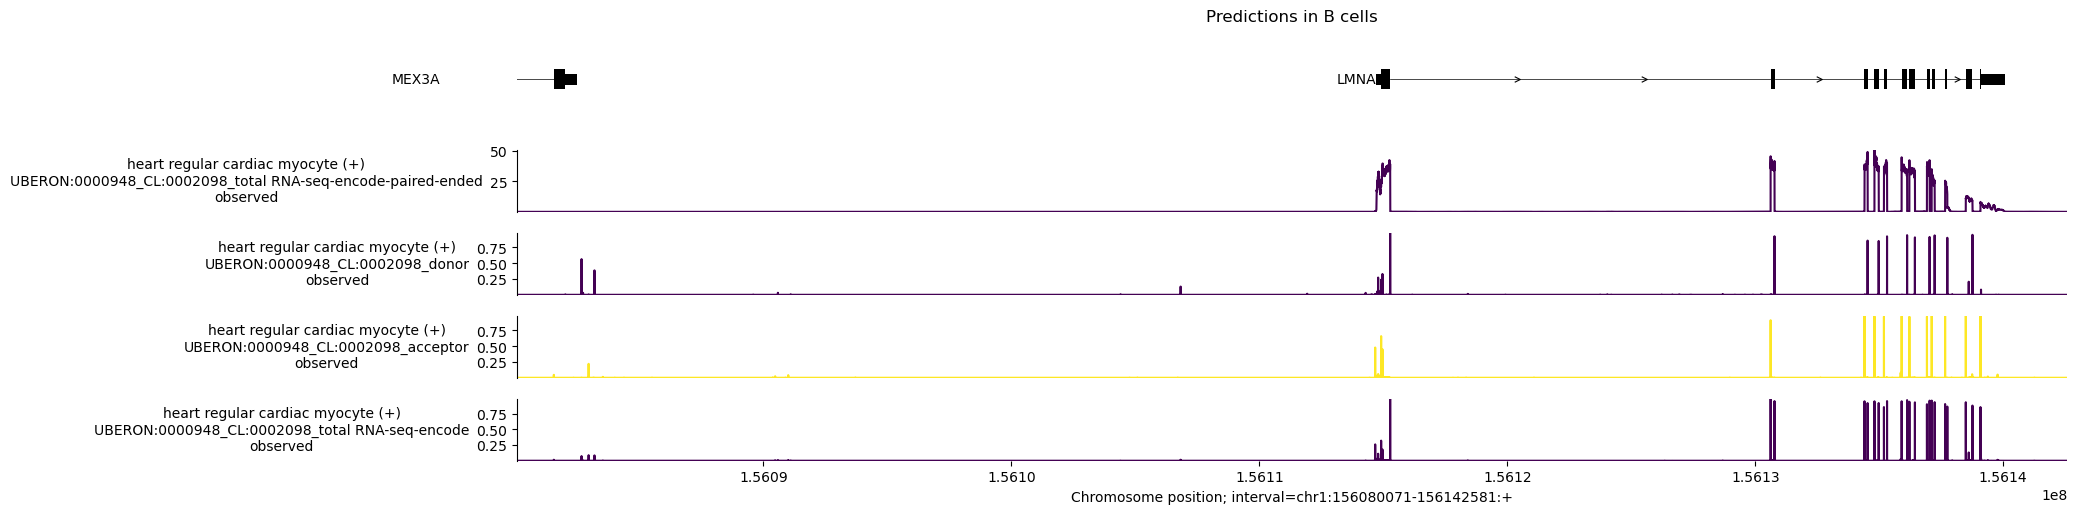

In [59]:
# Extract transcripts.
transcripts = transcript_extractor_mane.extract(interval)

# Plot.
plot_components.plot(
    components=[
        # Add transcripts to plot.
        plot_components.TranscriptAnnotation(transcripts),
        # Add RNA output.
        plot_components.Tracks(
            rna_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        # Add splice sites output.
        plot_components.Tracks(
            splice_sites_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        # Add splice site usage output.
        plot_components.Tracks(
            splice_site_usage_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        
    ],
    interval=gene_interval.resize(gene_interval.width + 5000),
    title='Predictions in B cells',
)

plt.show()

# Predict interval (Pseudobulk)

In [61]:
output_sc = dna_model.predict_interval(
    interval=interval,  # Same interval.
    requested_outputs=[
        dna_client.OutputType.SC_GENE_EXPRESSION,  # SC RNA.
        dna_client.OutputType.SC_ATAC,
    ],  # SC ATAC.
    condition=target_condition,  # Same condition.
)

In [62]:
output_sc.sc_atac.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,suspension_type,data_pipeline
0,UBERON:0000948_CL:0002098_EasySci-ATAC-easy_sci-nuclear,.,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,EasySci-ATAC,nuclear,easy_sci
1,UBERON:0000948_CL:0002098_SHARE-seq-cellranger-nuclear,.,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,SHARE-seq,nuclear,cellranger
2,UBERON:0000948_CL:0002098_scATAC-seq 10X-bowtie2-nuclear,.,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,scATAC-seq 10X,nuclear,encode
3,UBERON:0000948_CL:0002098_scATAC-seq 10X-cellranger-nuclear,.,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,scATAC-seq 10X,nuclear,cellranger
4,UBERON:0000948_CL:0002098_sciATAC-seq-bowtie2-nuclear,.,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,sciATAC-seq,nuclear,encode


In [63]:
# View track metadata for sc gene expression.
output_sc.sc_gene_expression.track_metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,suspension_type,data_pipeline
0,UBERON:0000948_CL:0002098_EasySci-easy_sci-nuclear,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,EasySci,nuclear,easy_sci
1,UBERON:0000948_CL:0002098_SHARE-seq-share_seq-nuclear,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,SHARE-seq,nuclear,share_seq
2,UBERON:0000948_CL:0002098_SPLIT-seq-star_solo-nuclear,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,SPLIT-seq,nuclear,encode
3,UBERON:0000948_CL:0002098_scRNA-seq 10X 3-cellranger-cell,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,scRNA-seq 10X 3,cell,cellranger
4,UBERON:0000948_CL:0002098_scRNA-seq 10X 3-cellranger-nuclear,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,scRNA-seq 10X 3,nuclear,cellranger
5,UBERON:0000948_CL:0002098_scRNA-seq 10X 3-star_solo-nuclear,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,scRNA-seq 10X 3,nuclear,encode
6,UBERON:0000948_CL:0002098_scRNA-seq 10X 5-cellranger-cell,+,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,scRNA-seq 10X 5,cell,cellranger
7,UBERON:0000948_CL:0002098_EasySci-easy_sci-nuclear,-,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,EasySci,nuclear,easy_sci
8,UBERON:0000948_CL:0002098_SHARE-seq-share_seq-nuclear,-,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,SHARE-seq,nuclear,share_seq
9,UBERON:0000948_CL:0002098_SPLIT-seq-star_solo-nuclear,-,UBERON:0000948_CL:0002098,imputed_supported,primary_cell,heart regular cardiac myocyte,SPLIT-seq,nuclear,encode


In [64]:
# View gene metadata for sc gene expression.
output_sc.sc_gene_expression.gene_metadata

,gene_id,Chromosome,Start,End,strand,gene_name,gene_type
0,ENSG00000116580.20,chr1,155749658,155859400,-,GON4L,protein_coding
1,ENSG00000116584.22,chr1,155946850,156007070,-,ARHGEF2,protein_coding
2,ENSG00000116586.12,chr1,156054781,156058506,+,LAMTOR2,protein_coding
3,ENSG00000116604.19,chr1,156463726,156500779,-,MEF2D,protein_coding
4,ENSG00000125459.18,chr1,155563234,155614951,+,MSTO1,protein_coding
5,ENSG00000125462.20,chr1,156404249,156456763,-,MIR9-1HG,lncRNA
6,ENSG00000132676.16,chr1,155687959,155739010,+,DAP3,protein_coding
7,ENSG00000132677.13,chr1,156369210,156385219,+,RHBG,protein_coding
8,ENSG00000132680.11,chr1,155913044,155934413,-,KHDC4,protein_coding
9,ENSG00000132698.15,chr1,156061159,156070504,+,RAB25,protein_coding


## Subset tracks

In [67]:
# Subset single-cell gene expression to positive-strand protein-coding genes and observed + tracks.
sc_rna_subset = (
    output_sc.sc_gene_expression.filter_to_protein_coding()
    # .filter_to_observed()
    .filter_to_positive_strand()
)
sc_rna_subset = sc_rna_subset[sc_rna_subset.gene_metadata['strand'] == '+']

# Subset scATAC to observed tracks.
mask_sc_atac = (
    (output_sc.sc_atac.metadata['imputation_mode'] == 'imputed_supported')
).values
sc_atac_subset = output_sc.sc_atac[:, mask_sc_atac]

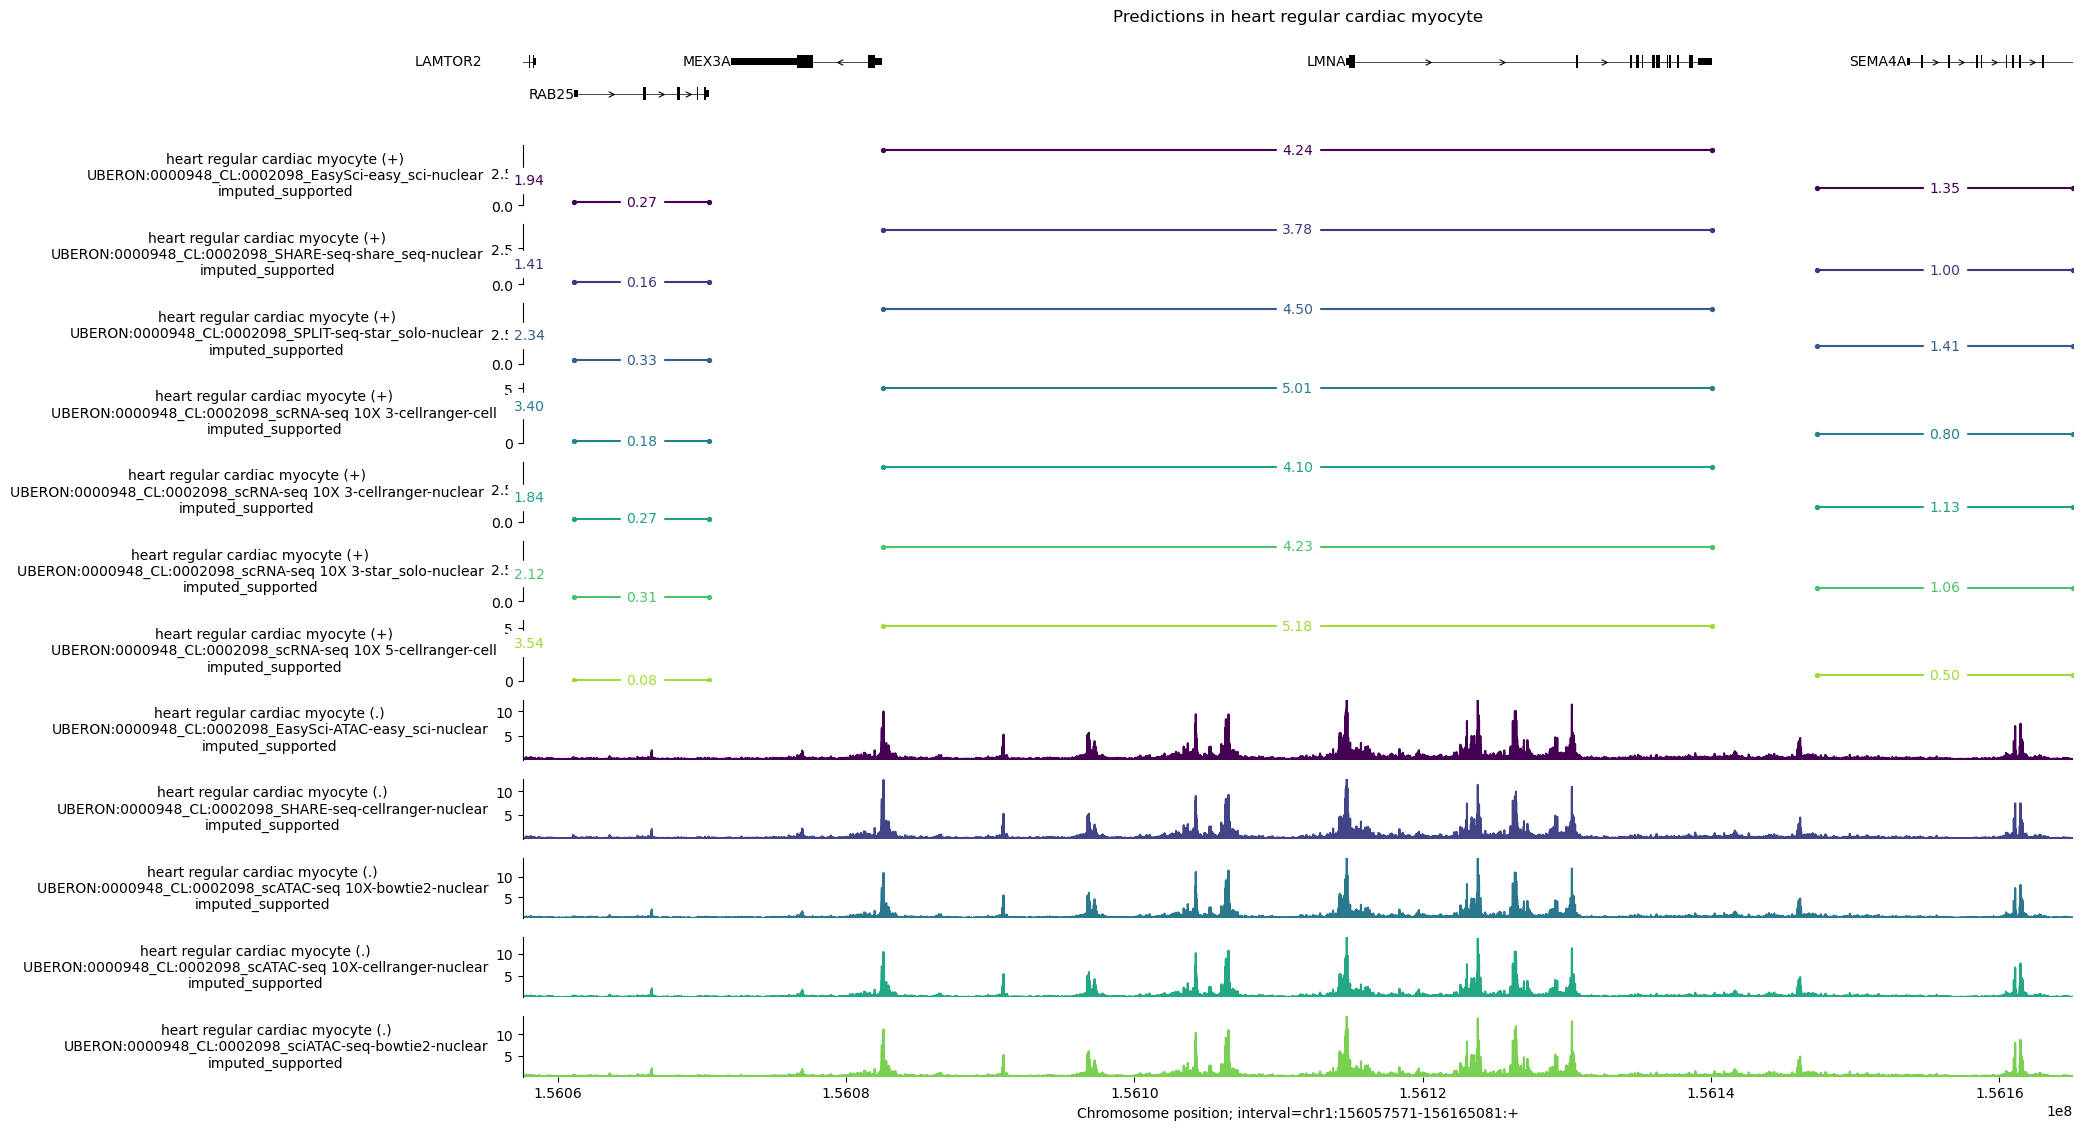

In [69]:
# Extract transcripts.
transcripts = transcript_extractor_mane.extract(interval)

# Plot.
plot_components.plot(
    components=[
        # Add transcripts to plot.
        plot_components.TranscriptAnnotation(transcripts),
        # Add single cell RNA output.
        plot_components.GeneExpression(
            sc_rna_subset,
            log_scale=True,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        # Add single cell ATAC output.
        plot_components.Tracks(
            sc_atac_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 50000),
    title='Predictions in heart regular cardiac myocyte',
)

plt.show()

# Predict for multiple conditions at once

In [19]:
conditions = [
    'UBERON:0002084_CL:0000746',
    'UBERON:0000948_CL:0000746',
    'UBERON:0000948_CL:0002098'

]

In [20]:
output = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={
            dna_client.OutputType.SC_GENE_EXPRESSION,
        },
        condition=condition,
    )
    for condition in conditions
]

In [33]:
# Concatenate predictions for the two queried ontologies
gex_pred = gene_expression_data.concat(
    [out.sc_gene_expression for out in output]
)

# Select only protein-coding genes and observed, negative strand tracks.
gex_pred = (
    gex_pred.filter_to_protein_coding()
    .filter_to_positive_strand()
)

# Extract the longest transcripts per gene for this interval.
longest_transcripts = longest_transcript_extractor.extract(interval)

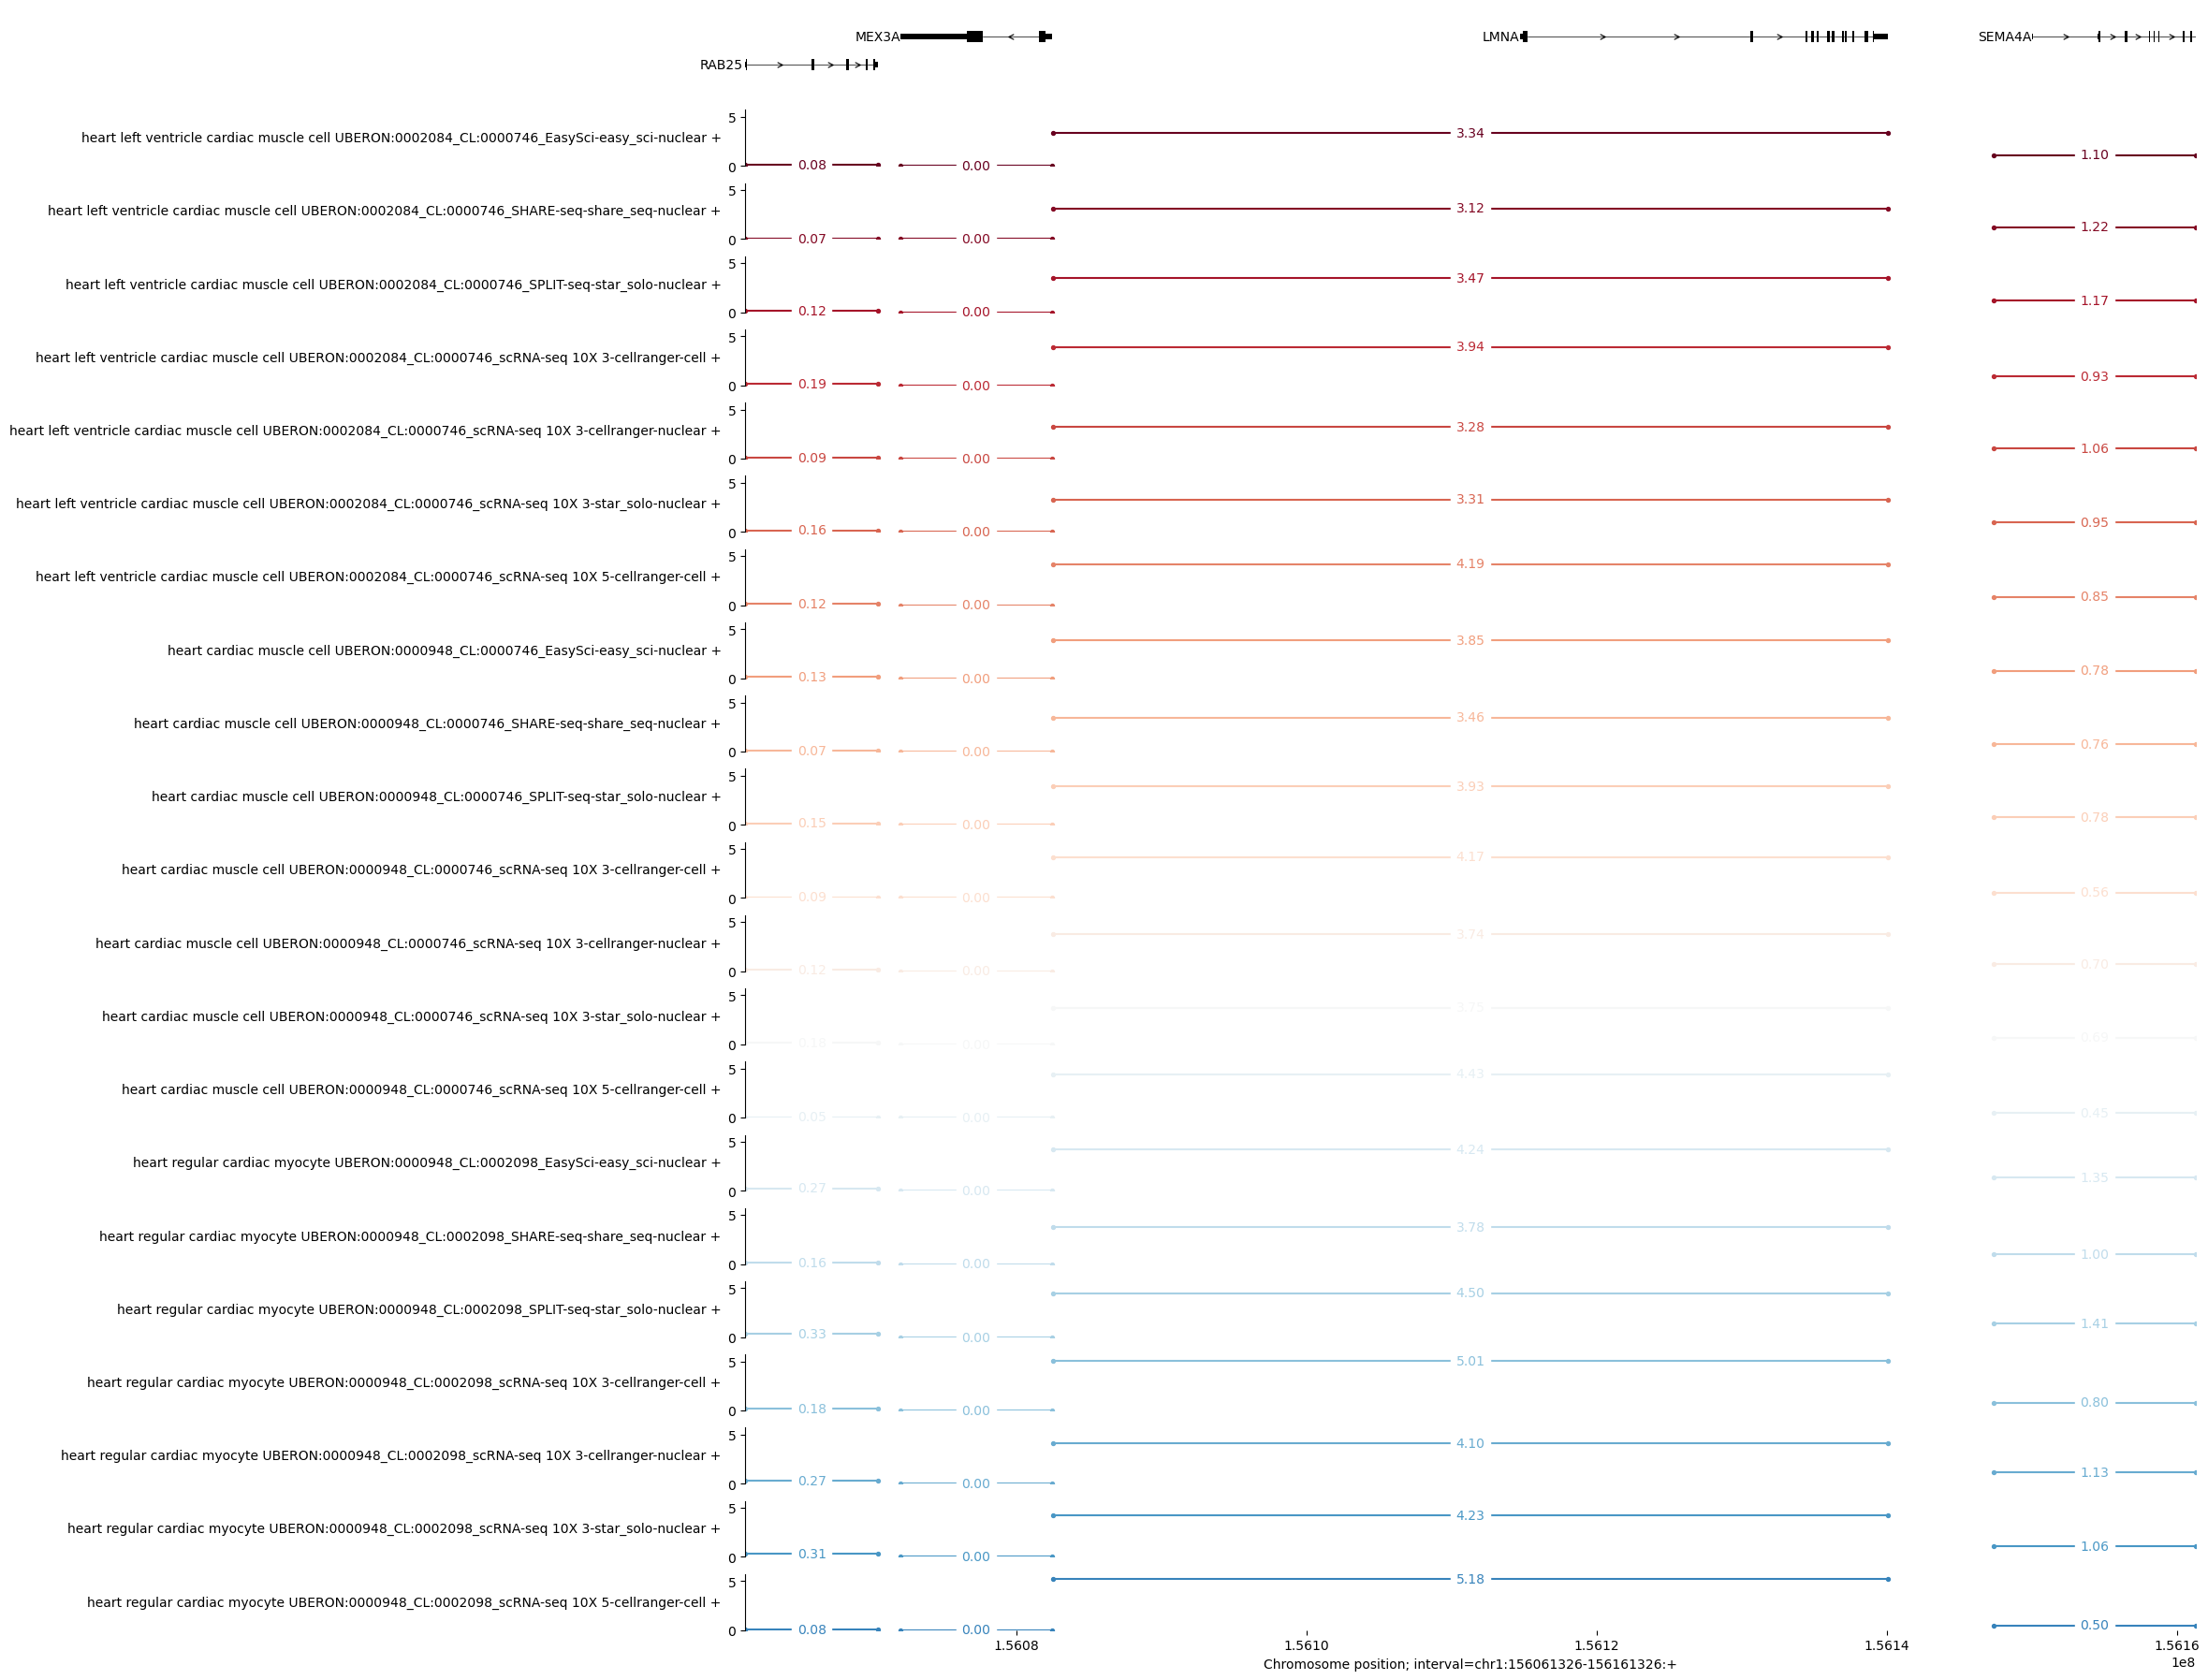

In [35]:
plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.GeneExpression(
            gdata=gex_pred,
            ylabel_template='{biosample_name} {name} {strand}',
            cmap='RdBu',
            log_scale=True,
            shared_y_scale=True,
        ),
    ],
    interval=interval.resize(100_000), 
)
plt.show()

In [36]:
# Make predictions.
outputs = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={dna_client.OutputType.CHIP_HISTONE},
        condition=condition,
    )
    for condition in conditions
]

In [37]:
gtf_tss = gene_annotation.extract_tss(gtf_longest_transcript)

tss_as_intervals = [
    genome.Interval(
        chromosome=row.Chromosome,
        start=row.Start,
        end=row.End + 1000,  # Add extra 1Kb so the TSSs are visible.
        name=row.gene_name,
    )
    for _, row in gtf_tss.iterrows()
]

In [38]:
concatenated_outputs = track_data.concat(
    [output.chip_histone for output in outputs]
)
reordered_chip_histone = concatenated_outputs.select_tracks_by_index(
    concatenated_outputs.metadata.sort_values('histone_mark').index
)

histone_to_color = {
    'H3K27AC': '#e41a1c',
    'H3K36ME3': '#ff7f00',
    'H3K4ME1': '#377eb8',
    'H3K4ME3': '#984ea3',
    'H3K9AC': '#4daf4a',
    'H3K27ME3': '#ffc0cb',
}
track_colors = (
    reordered_chip_histone.metadata['histone_mark']
    .map(lambda x: histone_to_color.get(x.upper(), '#000000'))
    .values
)

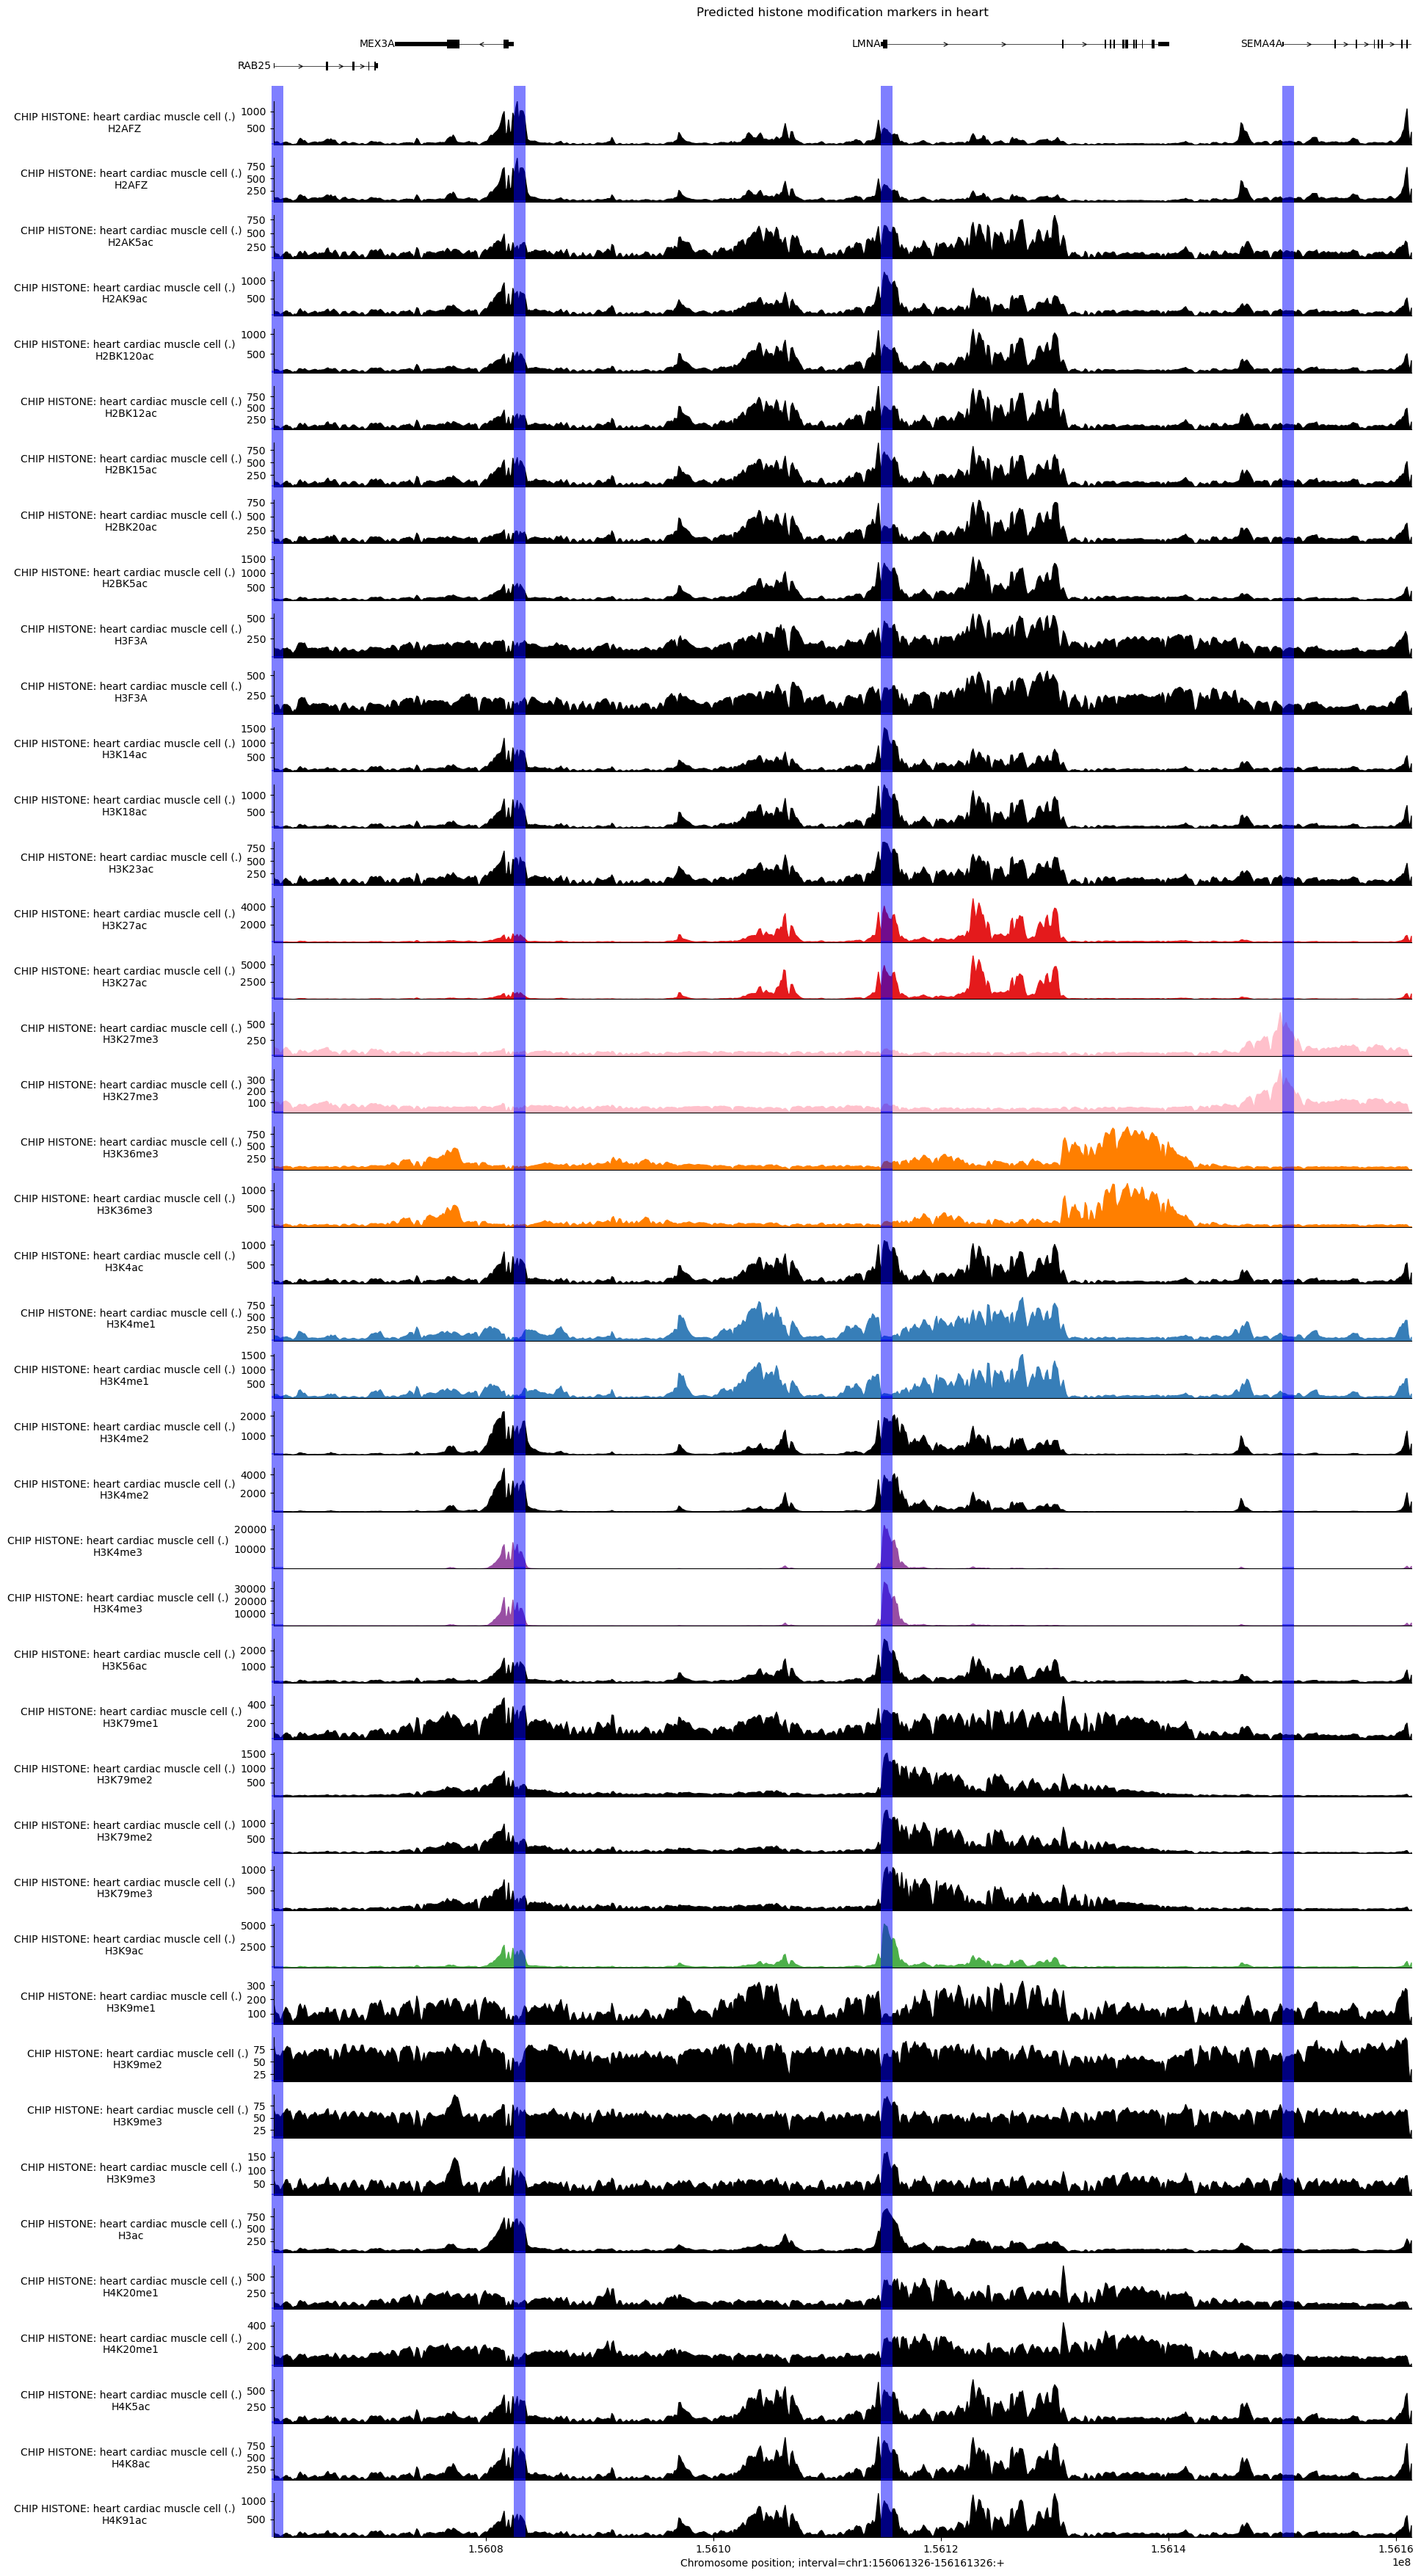

In [43]:
# Build plot.
observed_tracks_mask = (
    (reordered_chip_histone.metadata['imputation_mode'] == 'observed')
    | (reordered_chip_histone.metadata['imputation_mode'] == 'imputed_supported')
).values
plot = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=reordered_chip_histone.filter_tracks(observed_tracks_mask),
            ylabel_template=(
                'CHIP HISTONE: {biosample_name} ({strand})\n{histone_mark}'
            ),
            filled=True,
            track_colors=track_colors[observed_tracks_mask],
        ),
    ],
    interval=interval.resize(100_000),
    annotations=[
        plot_components.IntervalAnnotation(
            tss_as_intervals, alpha=0.5, colors='blue'
        )
    ],
    despine_keep_bottom=True,
    title='Predicted histone modification markers in heart',
)

## TF ChIP-seq

In [44]:
outputs = [
    dna_model.predict_interval(
        interval=interval,
        requested_outputs={dna_client.OutputType.CHIP_TF},
        condition=condition,
    )
    for condition in conditions
]

concatenated_chip_tf = track_data.concat([output.chip_tf for output in outputs])

In [45]:
output_chip_tf = concatenated_chip_tf.filter_tracks(
    (concatenated_chip_tf.metadata['biosample_curie'].isin(conditions)).values
)
len(output_chip_tf.metadata)

2733

In [46]:
max_predictions = output_chip_tf.metadata[
    ['biosample_curie', 'biosample_name', 'transcription_factor']
].copy()

max_predictions.loc[:, 'max_prediction'] = output_chip_tf.values.max(axis=0)
max_predictions.sort_values('max_prediction', ascending=False).reset_index(
    drop=True
)

,biosample_curie,biosample_name,transcription_factor,max_prediction
0,UBERON:0000948_CL:0000746,heart cardiac muscle cell,CTCF,19112.808594
1,UBERON:0000948_CL:0000746,heart cardiac muscle cell,CTCF,12415.032227
2,UBERON:0000948_CL:0002098,heart regular cardiac myocyte,CTCF,9095.768555
3,UBERON:0000948_CL:0000746,heart cardiac muscle cell,ZNF654,8565.726562
4,UBERON:0000948_CL:0000746,heart cardiac muscle cell,RAD21,8154.647949
5,UBERON:0000948_CL:0000746,heart cardiac muscle cell,SMC3,6410.399414
6,UBERON:0000948_CL:0000746,heart cardiac muscle cell,SMC3,6227.011719
7,UBERON:0000948_CL:0002098,heart regular cardiac myocyte,CTCF,6218.382324
8,UBERON:0000948_CL:0000746,heart cardiac muscle cell,RAD21,4728.269531
9,UBERON:0000948_CL:0002098,heart regular cardiac myocyte,RAD21,4659.058105


In [47]:
print(f'Number of tracks before filtering: {len(output_chip_tf.metadata)}')

output_filtered = output_chip_tf.filter_tracks(
    output_chip_tf.values.max(axis=0) > 10_000
)
print(f'Number of tracks after filtering: {len(output_filtered.metadata)}')

Number of tracks before filtering: 2733
Number of tracks after filtering: 2


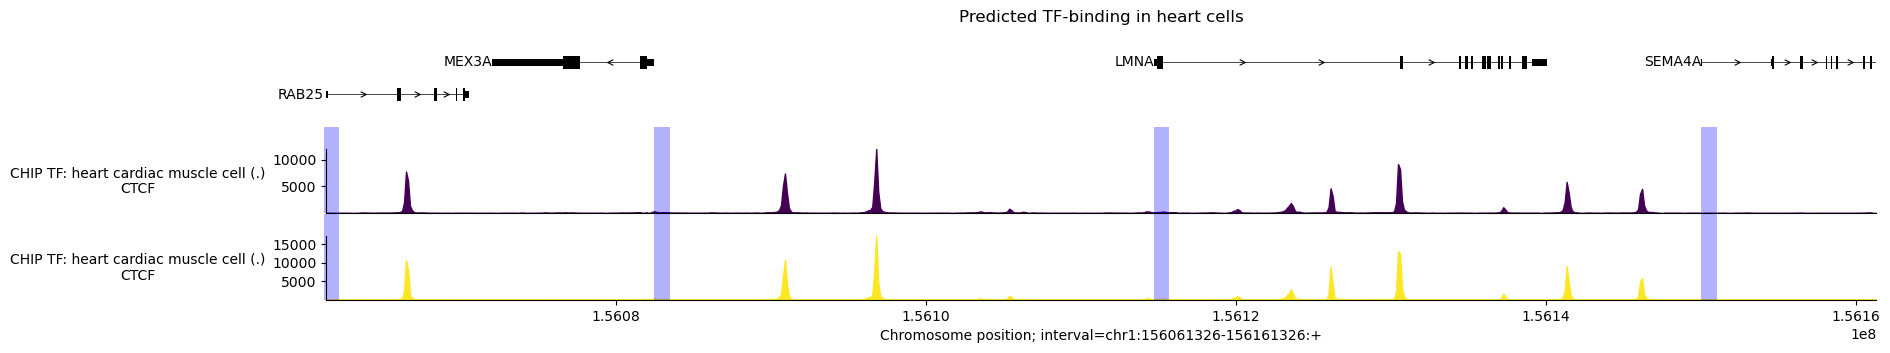

In [50]:
# Build plot.
plot_components.plot(
    components=[
        plot_components.TranscriptAnnotation(longest_transcripts),
        plot_components.Tracks(
            tdata=output_filtered,
            ylabel_template=(
                'CHIP TF: {biosample_name} ({strand})\n{transcription_factor}'
            ),
            filled=True,
        ),
    ],
    interval=interval.resize(100_000),
    title='Predicted TF-binding in heart cells',
    despine_keep_bottom=True,
    annotations=[
        plot_components.IntervalAnnotation(
            tss_as_intervals, alpha=0.3, colors='blue'
        )
    ],
)
plt.show()